In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from sqlalchemy import create_engine

PROJECT_DIR = Path("..").resolve()
SQL_DIR = PROJECT_DIR / "sql"
OUTPUT_DIR = PROJECT_DIR / "output"

db_path = (PROJECT_DIR / "data" / "retail.db").as_posix()
engine = create_engine(f"sqlite:///{db_path}")
print(engine)

Engine(sqlite:///C%3A/Users/nick/Documents/Claude/retail-customer-analytics-sql-python/data/retail.db)


In [2]:
def read_queries(path):
    """Return the queries in a SQL file as a dictionary, keyed 'Q1', 'Q2' and so on.
    Each query must start with a comment line such as '-- Q1. Title'."""
    text = Path(path).read_text(encoding="utf-8")
    queries = {}
    for block in text.split("-- Q")[1:]:
        key = "Q" + block.split(".")[0]
        queries[key] = block.split("\n", 1)[1]
    return queries

overview = read_queries(SQL_DIR / "03_overview.sql")
print(list(overview))

['Q1', 'Q2', 'Q3']


In [3]:
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED,
    "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "font.size": 10,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "savefig.dpi": 150, "savefig.bbox": "tight",
})

In [4]:
headline = pd.read_sql(overview["Q1"], engine)
headline

,total_revenue,invoices,customers,repeat_rate_pct
0,19645617.81,39516,5852,72.4


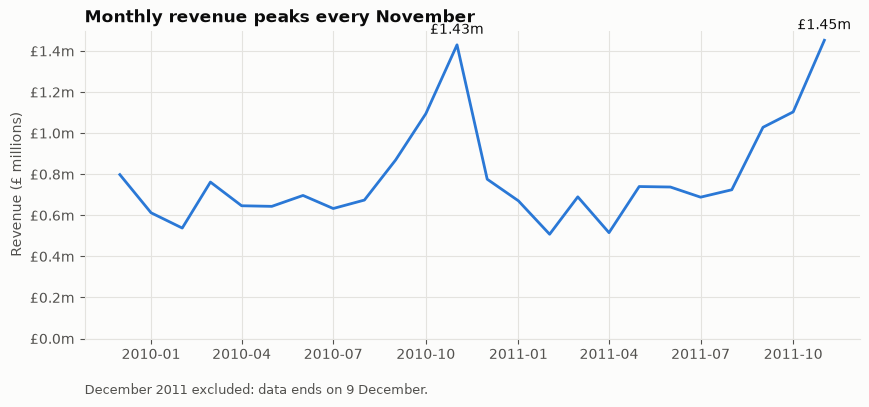

In [5]:
monthly = pd.read_sql(overview["Q2"], engine)
monthly["month"] = pd.to_datetime(monthly["month"])
full_months = monthly[monthly["month"] < "2011-12-01"]

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(full_months["month"], full_months["revenue"] / 1e6, color=BLUE, linewidth=2)
ax.set_title("Monthly revenue peaks every November")
ax.set_ylabel("Revenue (£ millions)")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("£{x:.1f}m"))
ax.set_ylim(0, None)

for peak in ["2010-11-01", "2011-11-01"]:
    value = full_months.loc[full_months["month"] == peak, "revenue"].iloc[0] / 1e6
    ax.annotate(f"£{value:.2f}m", (pd.Timestamp(peak), value),
                textcoords="offset points", xytext=(0, 8), ha="center")

ax.text(0, -0.18, "December 2011 excluded: data ends on 9 December.",
        transform=ax.transAxes, color=MUTED, fontsize=9)
fig.savefig(OUTPUT_DIR / "chart1_monthly_revenue.png")
plt.show()

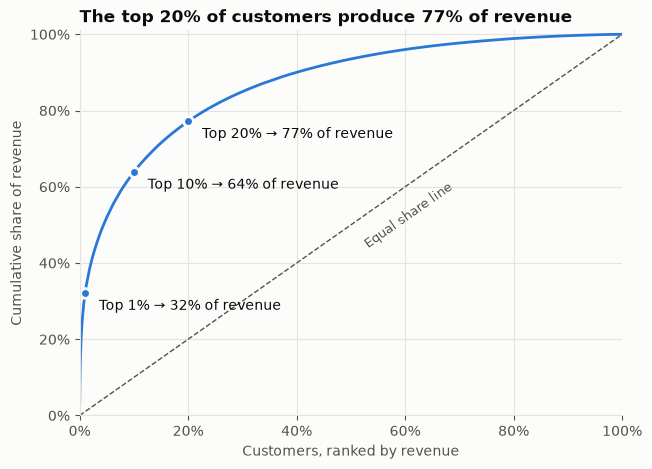

In [6]:
pareto = pd.read_sql(overview["Q3"], engine)

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(pareto["pct_customers"], pareto["pct_revenue"], color=BLUE, linewidth=2)
ax.plot([0, 100], [0, 100], color=MUTED, linewidth=1, linestyle="--")
ax.text(52, 44, "Equal share line", color=MUTED, rotation=35, fontsize=9)

for top in (1, 10, 20):
    row = pareto[pareto["pct_customers"] >= top].iloc[0]
    ax.plot(row["pct_customers"], row["pct_revenue"], "o", color=BLUE,
            markersize=7, markeredgecolor=SURFACE, markeredgewidth=2)
    ax.annotate(f"Top {top}% → {row['pct_revenue']:.0f}% of revenue",
                (row["pct_customers"], row["pct_revenue"]),
                textcoords="offset points", xytext=(10, -12))

ax.set_xlim(0, 100)
ax.set_ylim(0, 101)
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_xlabel("Customers, ranked by revenue")
ax.set_ylabel("Cumulative share of revenue")
ax.set_title("The top 20% of customers produce 77% of revenue")
fig.savefig(OUTPUT_DIR / "chart2_revenue_concentration.png")
plt.show()